# News topic classification with TF-IDF and linear models

Classify news articles into five topics (**Politics, Sport, Technology, Entertainment, Business**) using a **TF-IDF vectorizer implemented from scratch** and two linear classifiers (**LinearSVC** and **Logistic Regression**). Course: Information Retrieval, University of Tehran.

**Pipeline:** preprocessing -> stratified 70/15/15 split -> TF-IDF (unigrams, then unigrams + bigrams) -> hyperparameter search on the validation set -> retrain the best model on train + validation -> evaluate once on the test set.

**Data:** 2,225 articles in `df_file.csv` with columns `Text` and `Label` (0 Politics, 1 Sport, 2 Technology, 3 Entertainment, 4 Business). The file is not included in this repository; put it next to this notebook to re-run it.

**Note:** the outputs below were produced by the original run. Results are summarized and discussed at the end.

In [ ]:
#Libraries needed
import pandas as pd
import numpy as np
import re, math
import matplotlib.pyplot as plt
from collections import Counter
import seaborn as sns
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)
import nltk
from sklearn.preprocessing import normalize

# Download required resources
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')   # needed by newer NLTK versions; older versions simply report it as unavailable

## Task 1: preprocessing and split

* Preprocessing: lowercase, keep only the letters a-z and spaces, tokenize with NLTK, remove English stop words. The tokens are stored in a new column `tokens`.
* Random seed **42** (it fixes the shuffle and both splits, so the numbers below are reproducible).
* Two stratified splits: 70 % train / 30 % temporary, then the temporary part is halved into 15 % validation and 15 % test.
* `stratify=` keeps the **class proportions** the same in every split. The classes are not equally sized (for example, 77 Sport articles but 58 Entertainment articles in the test set), so stratification does not give every class 20 %. Without it, a split could by chance over- or under-represent a class and make the evaluation less reliable.

In [20]:
#Preprocess and Load
RANDOM_SEED = 42
df = pd.read_csv("df_file.csv")  
df = df.sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)

stop_words = set(stopwords.words('english'))

def preprocess(text):
    text = text.lower()
    text = re.sub(r'[^a-z ]', '', text)
    tokens = [w for w in word_tokenize(text) if w not in stop_words]
    return tokens

df['tokens'] = df['Text'].apply(preprocess)

#Split

train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df['Label'], random_state=RANDOM_SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['Label'], random_state=RANDOM_SEED)

print(f"Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")

Train=1557, Val=334, Test=334


## Task 2: TF-IDF from scratch

For a term *t* in document *d*, with *N* the number of training documents and *df(t)* the number of training documents that contain *t*:

$$ w_{t,d} = \bigl(1 + \ln \mathrm{tf}_{t,d}\bigr)\cdot \ln\frac{N}{\mathrm{df}(t)} $$

* `compute_df` counts each term once per document (it uses `set(tokens)`), so a word that occurs five times in one article still adds only 1 to its document frequency.
* `compute_tfidf` returns a matrix with one row per document and one column per vocabulary term. Terms that were not seen in training are ignored.
* The vocabulary, *N* and *df* come **only from the training set**. Validation and test documents are transformed with these training statistics, so no information leaks from them.
* Each document vector is L2-normalized afterwards (in `run_experiment`), which makes dot products behave like cosine similarity.
* **Bigram setting:** `add_bigrams` appends tokens such as `stock_market` to the unigram list, so the vocabulary holds unigrams and bigrams.

In [22]:
def compute_df(docs):
    df_count = Counter()
    for tokens in docs:
        unique_terms = set(tokens)
        for term in unique_terms:
            df_count[term] += 1
    return df_count

def compute_tfidf(docs, df_count, N, vocab_index):
    X = np.zeros((len(docs), len(vocab_index)))
    for i, tokens in enumerate(docs):
        tf = Counter(tokens)
        for term, f in tf.items():
            if term in vocab_index and f > 0:
                j = vocab_index[term]
                tf_weight = 1 + math.log(f)
                idf_weight = math.log(N / df_count[term])
                X[i, j] = tf_weight * idf_weight
    return X

## Task 3: models and model selection

For each TF-IDF setting, `run_experiment` trains and compares

* **LinearSVC** with C in {0.1, 1, 10}: finds the separating hyperplane with the widest margin. C trades margin width against training errors (small C = stronger regularization, large C = fit the training data harder).
* **Logistic Regression** with an L2 penalty and C in {0.1, 1, 10}: models class probabilities with a logistic function. C is the inverse regularization strength.

The configuration with the best **validation Macro-F1** is selected, retrained on train + validation, and scored **once** on the test set. The cell below runs both settings.

In [23]:
def add_bigrams(tokens):
    bigrams = [tokens[i] + "_" + tokens[i+1] for i in range(len(tokens)-1)]
    return tokens + bigrams

def run_experiment(use_bigrams=False):
    print("\n" + "="*70)
    print("TF–IDF setting:", "unigram+bigram" if use_bigrams else "unigram")
    print("="*70)

    if use_bigrams:
        train_tokens = train_df['tokens'].apply(add_bigrams)
        val_tokens   = val_df['tokens'].apply(add_bigrams)
        test_tokens  = test_df['tokens'].apply(add_bigrams)
    else:
        train_tokens, val_tokens, test_tokens = (
            train_df['tokens'], val_df['tokens'], test_df['tokens']
        )

    N = len(train_tokens)
    df_count = compute_df(train_tokens)
    vocab = sorted(df_count.keys())
    vocab_index = {term: i for i, term in enumerate(vocab)}

    X_train = compute_tfidf(train_tokens, df_count, N, vocab_index)
    X_val   = compute_tfidf(val_tokens,   df_count, N, vocab_index)
    X_test  = compute_tfidf(test_tokens,  df_count, N, vocab_index)
    X_train = normalize(X_train)
    X_val   = normalize(X_val)
    X_test  = normalize(X_test)

    y_train, y_val, y_test = (
        train_df['Label'].to_numpy(),
        val_df['Label'].to_numpy(),
        test_df['Label'].to_numpy()
    )

    best_score, best_model, best_name = 0, None, ""

    # Linear SVM
    for C in [0.1, 1, 10]:
        model = LinearSVC(C=C, random_state=RANDOM_SEED)
        model.fit(X_train, y_train)
        preds = model.predict(X_val)
        macro_f1 = precision_recall_fscore_support(
            y_val, preds, average='macro', zero_division=0)[2]
        print(f"LinearSVC C={C} → Macro-F1={macro_f1:.3f}")
        if macro_f1 > best_score:
            best_score, best_model, best_name = macro_f1, model, f"SVM (C={C})"

    # Logistic Regression
    for C in [0.1, 1, 10]:
        model = LogisticRegression(
            C=C, max_iter=2000, penalty='l2', random_state=RANDOM_SEED)
        model.fit(X_train, y_train)
        preds = model.predict(X_val)
        macro_f1 = precision_recall_fscore_support(
            y_val, preds, average='macro', zero_division=0)[2]
        print(f"LogReg C={C} → Macro-F1={macro_f1:.3f}")
        if macro_f1 > best_score:
            best_score, best_model, best_name = macro_f1, model, f"LogReg (C={C})"

    print(f"\n✅ Best model on validation: {best_name} with Macro-F1={best_score:.3f}")
    X_trainval = np.vstack([X_train, X_val])
    y_trainval = np.concatenate([y_train, y_val])
    best_model.fit(X_trainval, y_trainval)
    preds_test = best_model.predict(X_test)

    acc = accuracy_score(y_test, preds_test)
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_test, preds_test, average='macro', zero_division=0)

    print("\n--- Test Results ---")
    print(f"Accuracy={acc:.3f} | Macro-Precision={prec:.3f} | Macro-Recall={rec:.3f} | Macro-F1={f1:.3f}")
    print("\nPer-class metrics:")
    print(classification_report(
        y_test, preds_test, digits=3,
        target_names=['Politics','Sport','Tech','Entertainment','Business']))

    cm = confusion_matrix(y_test, preds_test)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Politics','Sport','Tech','Entertainment','Business'],
                yticklabels=['Politics','Sport','Tech','Entertainment','Business'])
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(f'Confusion Matrix - {best_name}')
    plt.show()

    return acc, prec, rec, f1




TF–IDF setting: unigram
LinearSVC C=0.1 → Macro-F1=0.975
LinearSVC C=1 → Macro-F1=0.984
LinearSVC C=10 → Macro-F1=0.984
LogReg C=0.1 → Macro-F1=0.931
LogReg C=1 → Macro-F1=0.978
LogReg C=10 → Macro-F1=0.984

✅ Best model on validation: LogReg (C=10) with Macro-F1=0.984

--- Test Results ---
Accuracy=0.973 | Macro-Precision=0.974 | Macro-Recall=0.973 | Macro-F1=0.974

Per-class metrics:
               precision    recall  f1-score   support

     Politics      0.937     0.937     0.937        63
        Sport      1.000     0.987     0.993        77
         Tech      0.983     0.983     0.983        60
Entertainment      1.000     1.000     1.000        58
     Business      0.948     0.961     0.954        76

     accuracy                          0.973       334
    macro avg      0.974     0.973     0.974       334
 weighted avg      0.973     0.973     0.973       334



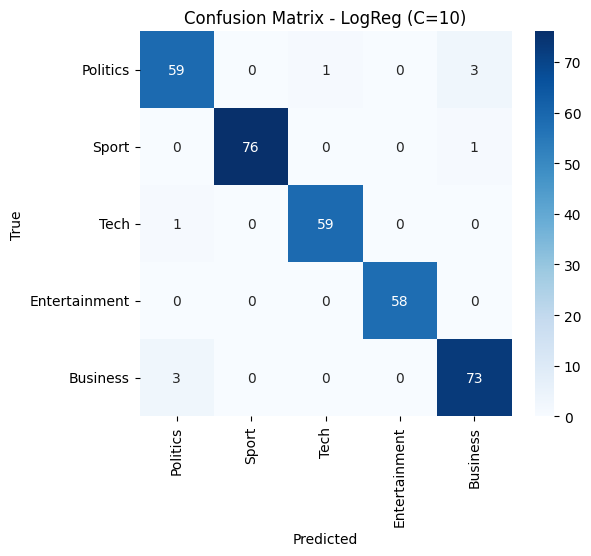


TF–IDF setting: unigram+bigram
LinearSVC C=0.1 → Macro-F1=0.969
LinearSVC C=1 → Macro-F1=0.972
LinearSVC C=10 → Macro-F1=0.975
LogReg C=0.1 → Macro-F1=0.726
LogReg C=1 → Macro-F1=0.969
LogReg C=10 → Macro-F1=0.972

✅ Best model on validation: SVM (C=10) with Macro-F1=0.975

--- Test Results ---
Accuracy=0.976 | Macro-Precision=0.976 | Macro-Recall=0.977 | Macro-F1=0.976

Per-class metrics:
               precision    recall  f1-score   support

     Politics      0.938     0.952     0.945        63
        Sport      1.000     0.987     0.993        77
         Tech      0.983     0.983     0.983        60
Entertainment      1.000     1.000     1.000        58
     Business      0.961     0.961     0.961        76

     accuracy                          0.976       334
    macro avg      0.976     0.977     0.976       334
 weighted avg      0.976     0.976     0.976       334



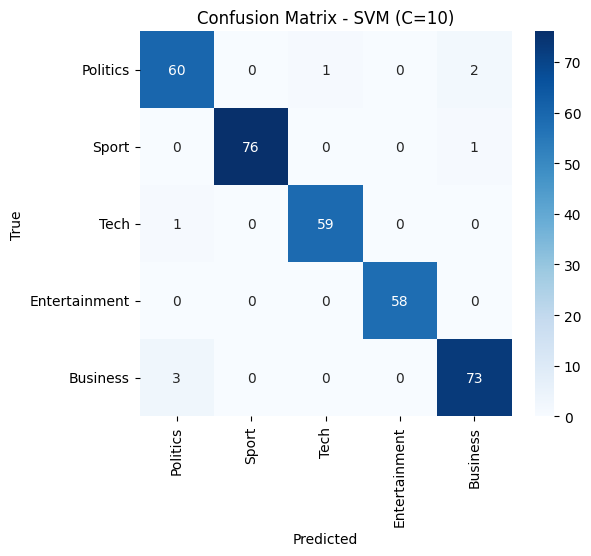


🔍 Results Summary
------------------------------------------------------
Setting                  Acc      Prec       Rec        F1
Unigram                0.973     0.974     0.973     0.974
Bigram                 0.976     0.976     0.977     0.976
------------------------------------------------------
Δ Macro-F1 (Bigram - Unigram): +0.003


In [24]:
uni_acc, uni_prec, uni_rec, uni_f1 = run_experiment(use_bigrams=False)
bi_acc, bi_prec, bi_rec, bi_f1 = run_experiment(use_bigrams=True)

# Summary table
print("\n🔍 Results Summary")
print("------------------------------------------------------")
print(f"{'Setting':<20}{'Acc':>8}{'Prec':>10}{'Rec':>10}{'F1':>10}")
print(f"{'Unigram':<20}{uni_acc:>8.3f}{uni_prec:>10.3f}{uni_rec:>10.3f}{uni_f1:>10.3f}")
print(f"{'Bigram':<20}{bi_acc:>8.3f}{bi_prec:>10.3f}{bi_rec:>10.3f}{bi_f1:>10.3f}")
print("------------------------------------------------------")
print(f"Δ Macro-F1 (Bigram - Unigram): {bi_f1 - uni_f1:+.3f}")

## Results and analysis

### Model selection (validation Macro-F1)

| Setting | LinearSVC C=0.1 / 1 / 10 | LogReg C=0.1 / 1 / 10 | Selected |
|---|---|---|---|
| Unigram | 0.975 / 0.984 / 0.984 | 0.931 / 0.978 / 0.984 | LogReg, C=10 (ties with the SVMs at 3 decimals) |
| Unigram + bigram | 0.969 / 0.972 / 0.975 | 0.726 / 0.969 / 0.972 | LinearSVC, C=10 |

Larger C is better in both settings. The one big drop is Logistic Regression with C=0.1 on bigram features (0.726): with a much larger, sparser feature space and strong regularization, the model is clearly under-fitted.

### Test results (334 articles)

| Setting | Accuracy | Macro-Precision | Macro-Recall | Macro-F1 |
|---|---|---|---|---|
| Unigram (LogReg, C=10) | 0.973 | 0.974 | 0.973 | 0.974 |
| Unigram + bigram (SVM, C=10) | 0.976 | 0.976 | 0.977 | 0.976 |

Per class (precision / recall / F1):

| Class | Unigram | Unigram + bigram |
|---|---|---|
| Politics | 0.937 / 0.937 / 0.937 | 0.938 / 0.952 / 0.945 |
| Sport | 1.000 / 0.987 / 0.993 | 1.000 / 0.987 / 0.993 |
| Tech | 0.983 / 0.983 / 0.983 | 0.983 / 0.983 / 0.983 |
| Entertainment | 1.000 / 1.000 / 1.000 | 1.000 / 1.000 / 1.000 |
| Business | 0.948 / 0.961 / 0.954 | 0.961 / 0.961 / 0.961 |

### Confusion matrices

Rows are the true classes and columns the predictions. Unigram: 9 of 334 articles are misclassified; unigram + bigram: 8.

* Entertainment is classified perfectly in both settings and Sport and Tech are almost perfect.
* **Politics and Business are the weak pair.** In the unigram model 6 of the 9 errors are Politics <-> Business (3 each way). This is plausible because political and economic news share a lot of vocabulary (government, tax, economy, ...), although the confusion matrix alone cannot prove that.
* The bigram model differs by exactly one article: one Politics article that was predicted as Business is now correct.

### Ablation: unigram vs. unigram + bigram

Macro-F1 changes by +0.003 on the test set (the notebook prints the unrounded difference; the values 0.974 and 0.976 above are rounded), which corresponds to **one article out of 334**. That is within the noise of a single split, so the honest conclusion is that bigrams do not help measurably here. (On the validation set the bigram setting was actually slightly lower, 0.975 vs. 0.984.) Individual words already separate these topics well, and bigrams add many extra, rarely occurring features. Note also that each setting used its own best model (Logistic Regression for unigrams, LinearSVC for bigrams), so this is a comparison of the two pipelines rather than of one fixed model.

### Could other classifiers be used?

These are expectations from how the methods work; they were not tested here.

* **SVM with an RBF or polynomial kernel** can learn curved decision boundaries, but training costs roughly O(n^2) to O(n^3) in the number of documents, and TF-IDF vectors with thousands of dimensions are usually already close to linearly separable (97 % accuracy here, though not perfectly separable). The extra flexibility would mainly add cost and over-fitting risk.
* **Neural networks on TF-IDF vectors** (for example an MLP) can learn interactions between words, but TF-IDF treats words independently, so a network would mostly re-learn what a linear model already captures. With 1.5k training articles I would expect similar results with more tuning effort.
* Models that use **word order and context** (pre-trained embeddings or transformers) are where larger gains could appear, for harder tasks with short, ambiguous or less topical text. On this nearly saturated task, there is little room to improve.